## Dataset Information

The training archive contains 25,000 images of dogs and cats. Train your algorithm on these files and predict the labels

(1 = dog, 0 = cat).

## Import Modules

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import tqdm
import random
from keras.preprocessing.image import load_img

warnings.filterwarnings('ignore')

## Create Dataframe for Input and Output

In [2]:
input_path = []
label = []


# Define the path to the directory
pet_images_dir = "PetImages"

# Create the directory if it doesn't exist
if not os.path.exists(pet_images_dir):
    os.makedirs(pet_images_dir)
    print(f"Created directory: {pet_images_dir}")
    # Optional: You might want to add subdirectories 'Cat' and 'Dog' as well
    # os.makedirs(os.path.join(pet_images_dir, 'Cat'))
    # os.makedirs(os.path.join(pet_images_dir, 'Dog'))

# Now proceed with reading the directory
for class_name in os.listdir(pet_images_dir):
    class_path = os.path.join(pet_images_dir, class_name)
    if os.path.isdir(class_path): # Check if it's a directory
        for path in os.listdir(class_path):
            if class_name == 'Cat':
                label.append(0)
            else:
                label.append(1)
            input_path.append(os.path.join(pet_images_dir, class_name, path))

# Check if input_path is populated before accessing index 0
if input_path:
    print(input_path[0], label[0])
else:
    print("PetImages directory is empty or does not contain subdirectories.")


PetImages/Cat/9733.jpg 0


In [3]:
df = pd.DataFrame()
df['images'] = input_path
df['label'] = label
df = df.sample(frac=1).reset_index(drop=True)
df.head()

,images,label
0,PetImages/Dog/8229.jpg,1
1,PetImages/Dog/36.jpg,1
2,PetImages/Dog/8592.jpg,1
3,PetImages/Dog/1803.jpg,1
4,PetImages/Cat/11078.jpg,0


In [4]:
for i in df['images']:
    if '.jpg' not in i:
        print(i)

PetImages/Dog/Thumbs.db
PetImages/Cat/Thumbs.db


In [5]:
import PIL
l = []
for image in df['images']:
    try:
        img = PIL.Image.open(image)
    except:
        l.append(image)
l

['PetImages/Dog/Thumbs.db', 'PetImages/Cat/Thumbs.db']

In [6]:
# delete db files
df = df[df['images']!='PetImages/Dog/Thumbs.db']
df = df[df['images']!='PetImages/Cat/Thumbs.db']
df = df[df['images']!='PetImages/Cat/666.jpg']
df = df[df['images']!='PetImages/Dog/11702.jpg']
len(df)

24959

## Exploratory Data Analysis

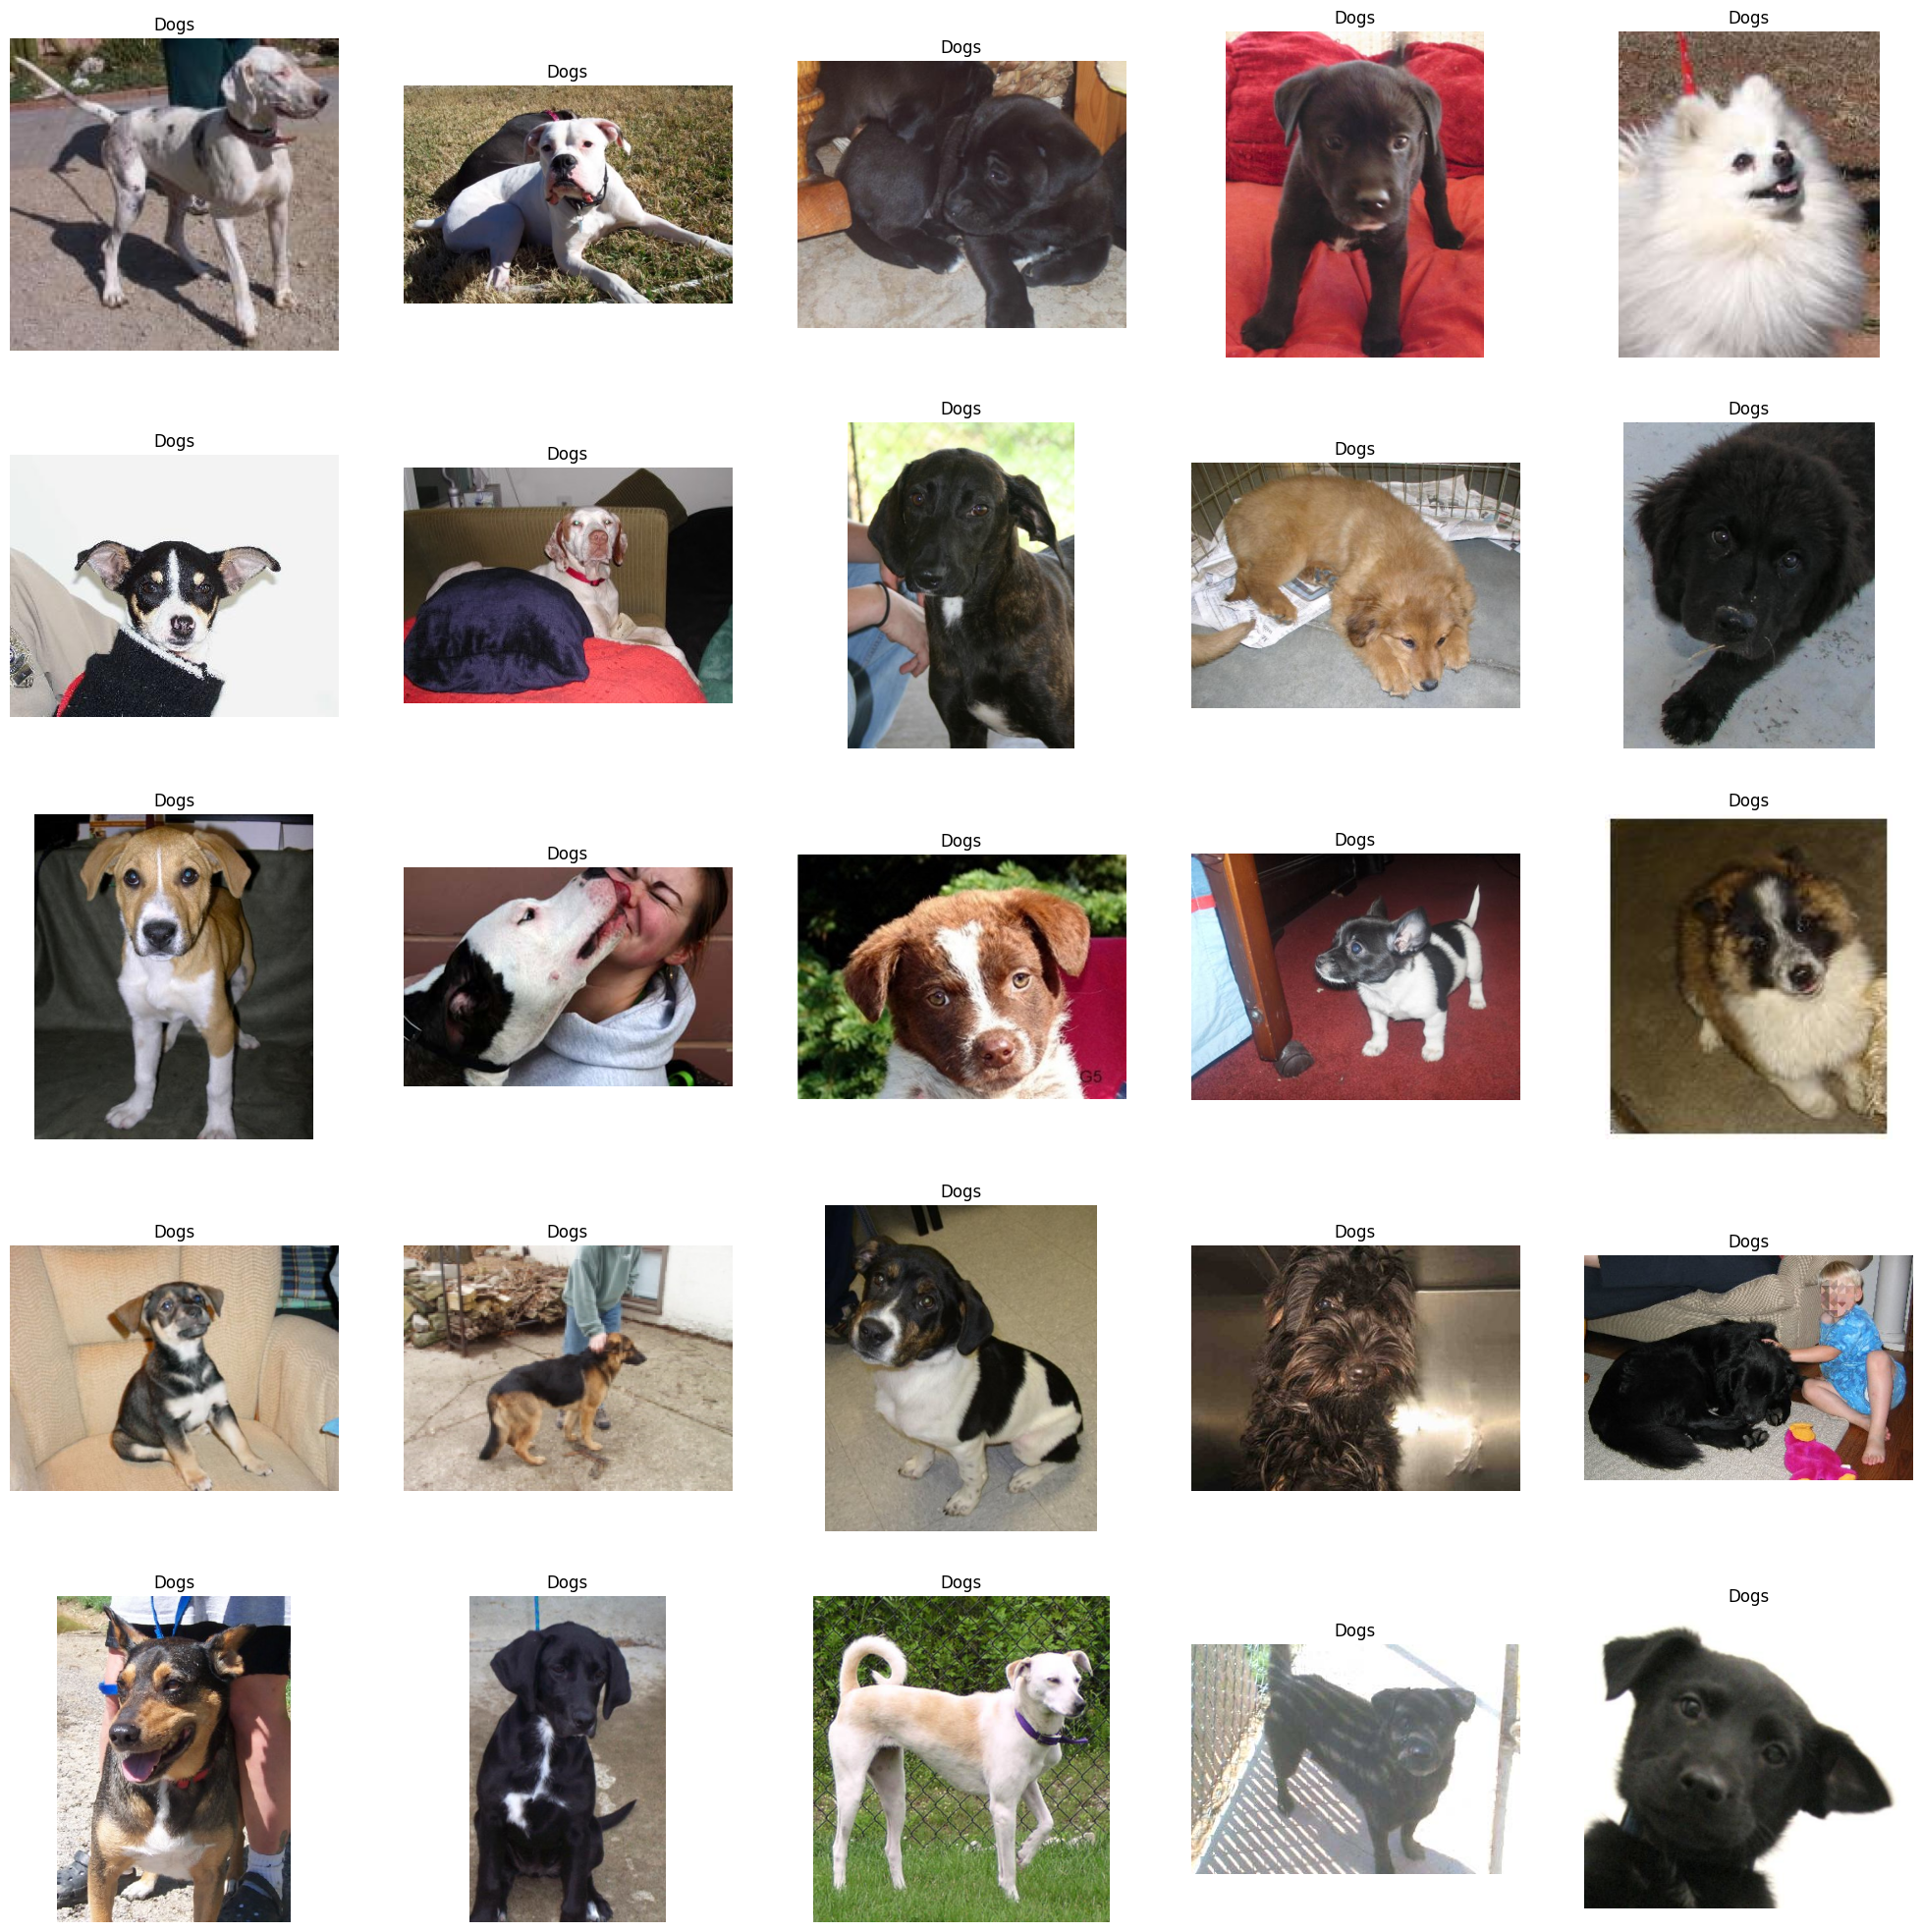

In [7]:
# to display grid of images
plt.figure(figsize=(25,25))
temp = df[df['label']==1]['images']
start = random.randint(0, len(temp))
files = temp[start:start+25]

for index, file in enumerate(files):
    plt.subplot(5,5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title('Dogs')
    plt.axis('off')

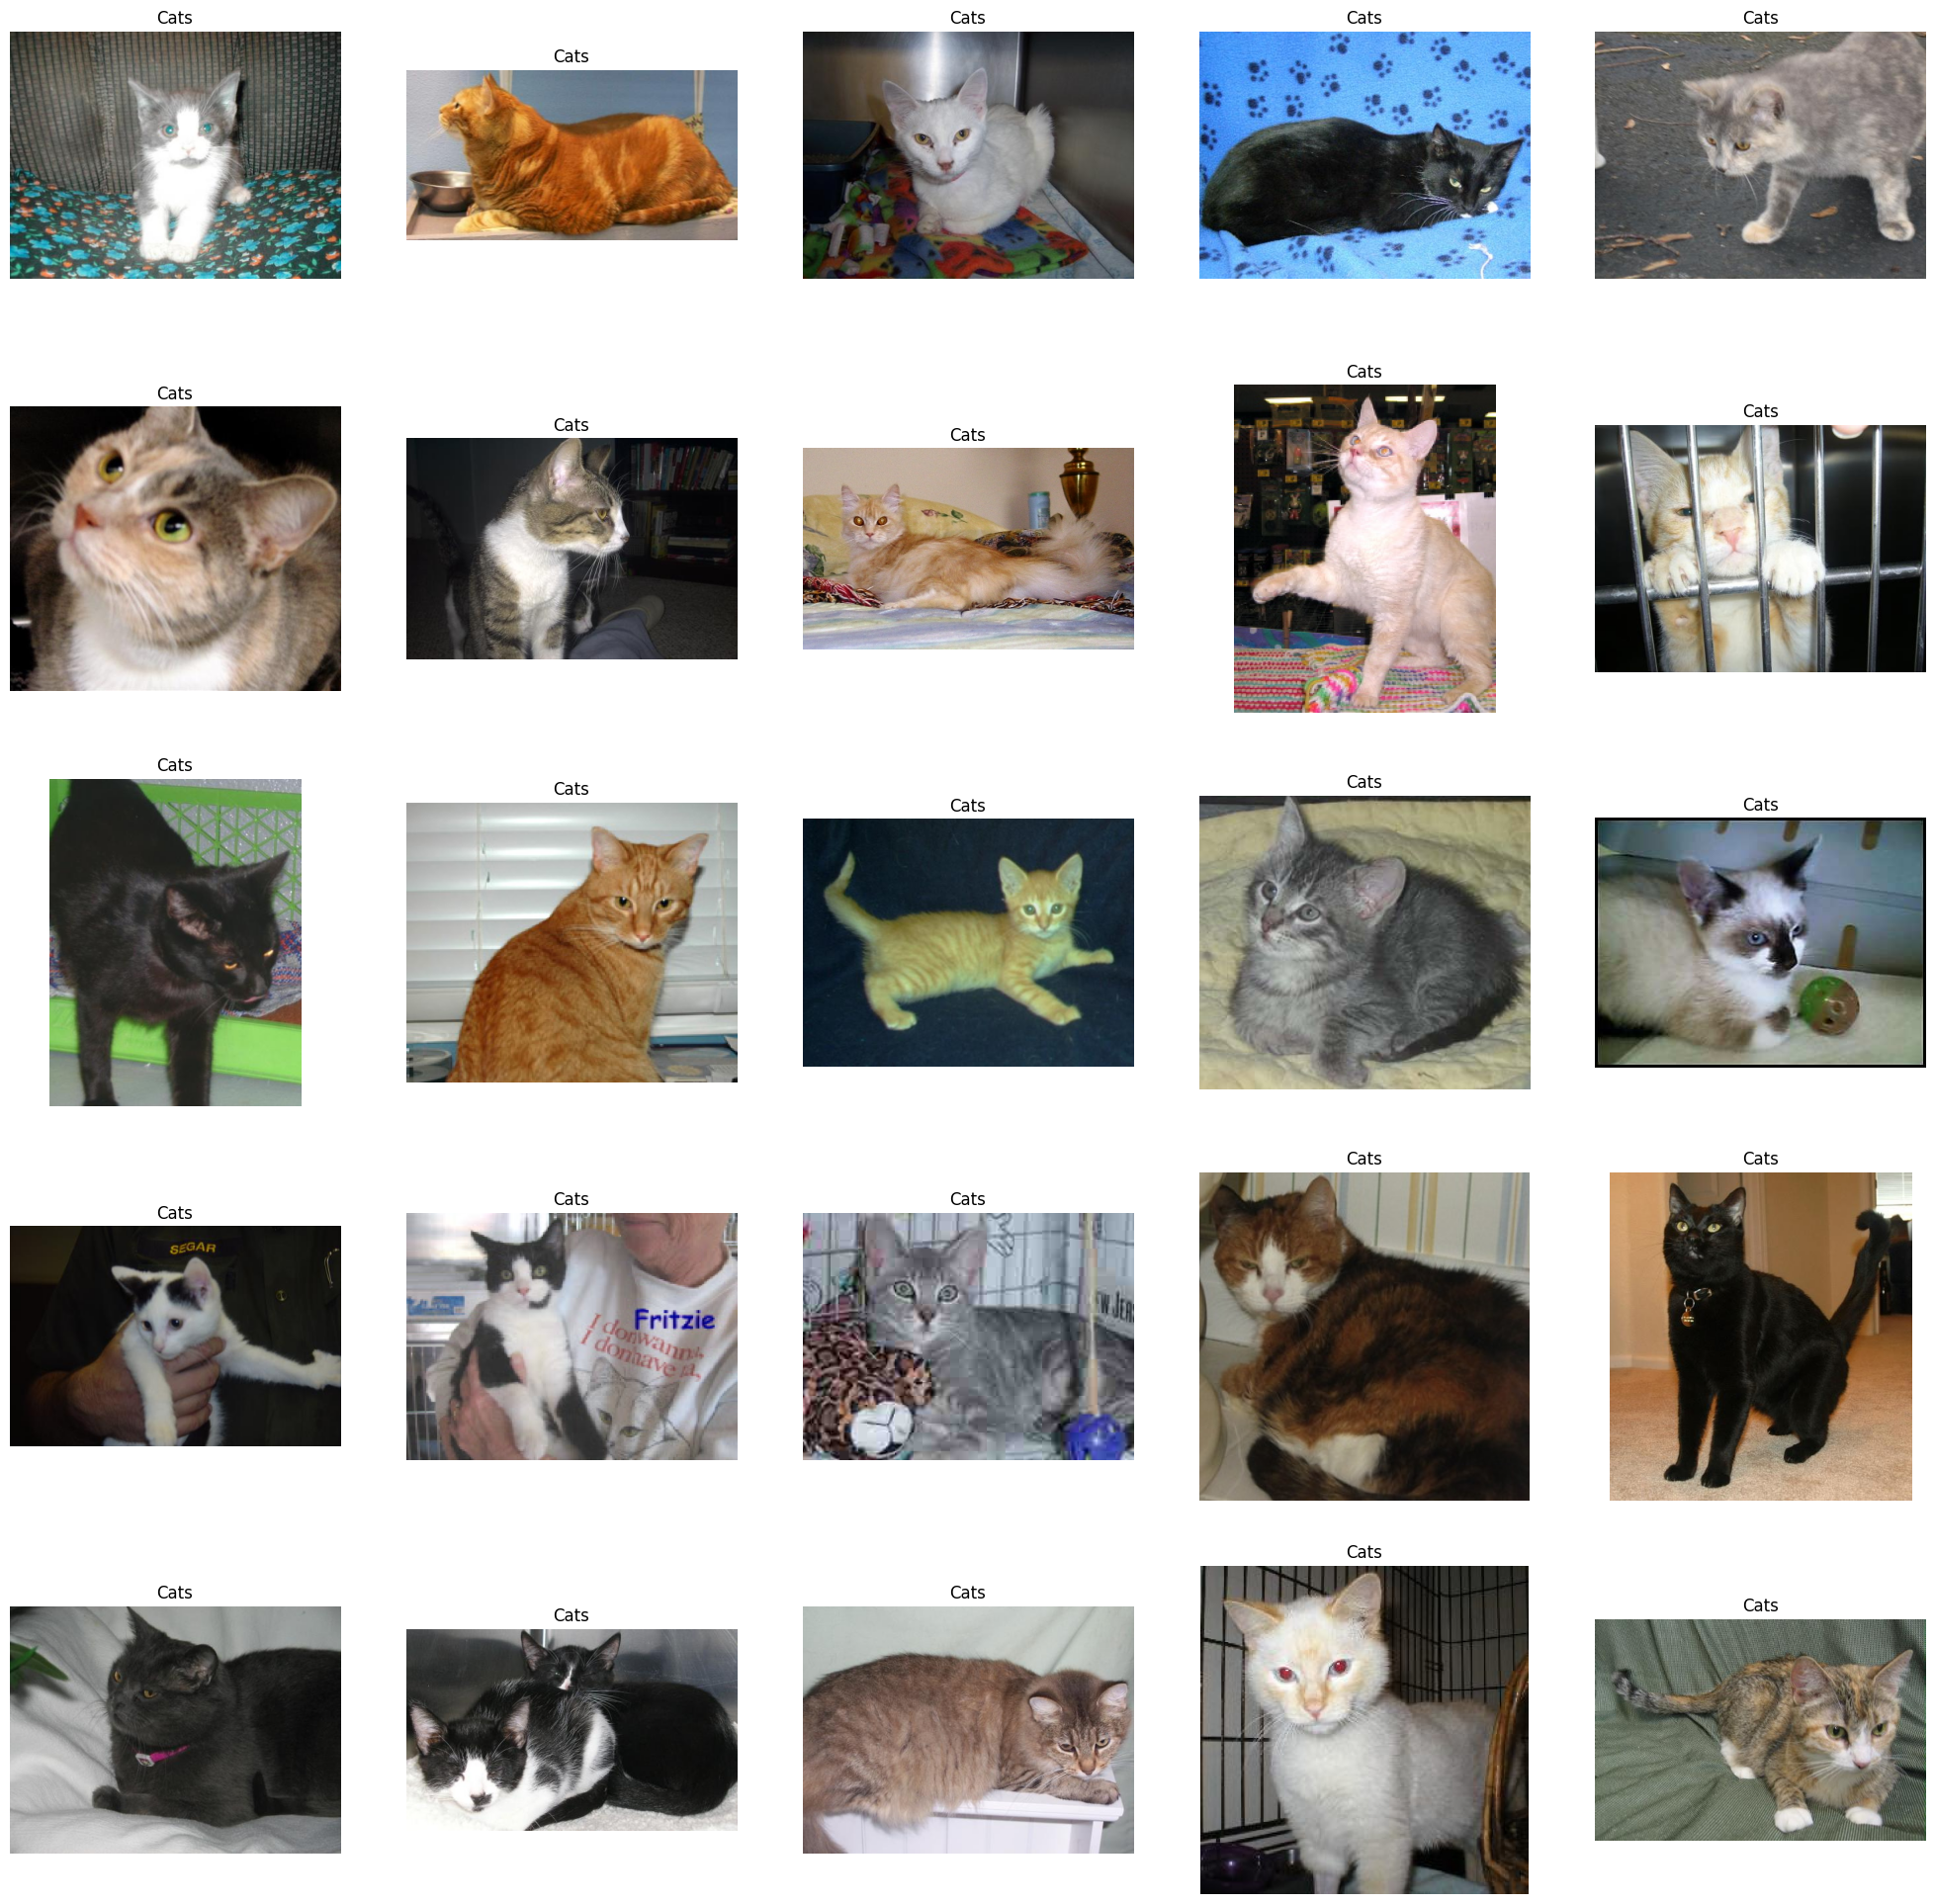

In [8]:
# to display grid of images
plt.figure(figsize=(25,25))
temp = df[df['label']==0]['images']
start = random.randint(0, len(temp))
files = temp[start:start+25]

for index, file in enumerate(files):
    plt.subplot(5,5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title('Cats')
    plt.axis('off')

<Axes: ylabel='count'>

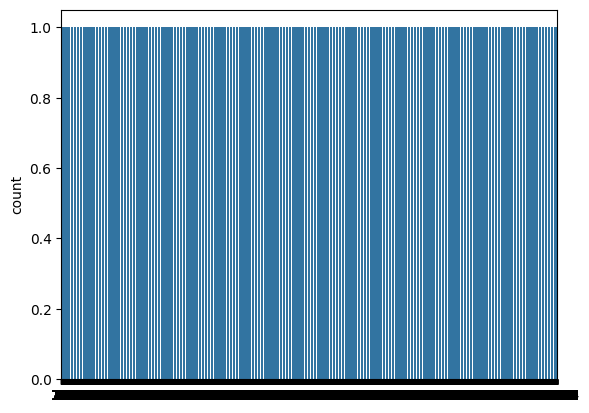

In [9]:
import seaborn as sns
sns.countplot(df['label'])

## Create DataGenerator for the Images

In [10]:
df['label'] = df['label'].astype('str')

In [11]:
df.head()

,images,label
0,PetImages/Dog/8229.jpg,1
1,PetImages/Dog/36.jpg,1
2,PetImages/Dog/8592.jpg,1
3,PetImages/Dog/1803.jpg,1
4,PetImages/Cat/11078.jpg,0


In [12]:
# input split
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.2, random_state=42)

In [15]:
#from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_generator = ImageDataGenerator(
    rescale = 1./255,  # normalization of images
    rotation_range = 40, # augmention of images to avoid overfitting
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    fill_mode = 'nearest'
)

val_generator = ImageDataGenerator(rescale = 1./255)

train_iterator = train_generator.flow_from_dataframe(
    train, 
    x_col='images', 
    y_col='label', 
    target_size=(128,128), 
    batch_size=512, 
    class_mode='binary'
)

val_iterator = val_generator.flow_from_dataframe(
    test, 
    x_col='images', 
    y_col='label', 
    target_size=(128,128), 
    batch_size=512, 
    class_mode='binary'
)

Found 19967 validated image filenames belonging to 2 classes.
Found 4992 validated image filenames belonging to 2 classes.


## Model Creation

In [16]:
from keras import Sequential
from keras.layers import Conv2D, MaxPool2D, Flatten, Dense

model = Sequential([
                    Conv2D(16, (3,3), activation='relu', input_shape=(128,128,3)),
                    MaxPool2D((2,2)),
                    Conv2D(32, (3,3), activation='relu'),
                    MaxPool2D((2,2)),
                    Conv2D(64, (3,3), activation='relu'),
                    MaxPool2D((2,2)),
                    Flatten(),
                    Dense(512, activation='relu'),
                    Dense(1, activation='sigmoid')
])

In [17]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,447,137 (24.59 MB)

 Trainable params: 6,447,137 (24.59 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(train_iterator, epochs=10, validation_data=val_iterator)

Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 243s 6s/step - accuracy: 0.5061 - loss: 0.8199 - val_accuracy: 0.5897 - val_loss: 0.6658
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 235s 6s/step - accuracy: 0.6118 - loss: 0.6545 - val_accuracy: 0.6671 - val_loss: 0.6030
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 281s 7s/step - accuracy: 0.6593 - loss: 0.6180 - val_accuracy: 0.6843 - val_loss: 0.5829
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 235s 6s/step - accuracy: 0.7025 - loss: 0.5707 - val_accuracy: 0.7390 - val_loss: 0.5239
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 227s 6s/step - accuracy: 0.7201 - loss: 0.5441 - val_accuracy: 0.7330 - val_loss: 0.5372
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 224s 6s/step - accuracy: 0.7262 - loss: 0.5428 - val_accuracy: 0.7476 - val_loss: 0.5040
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 224s 6s/step - accuracy: 0.7492 - loss: 0.5084 - val_accuracy: 0.7716 - val_loss: 0.4716
Epoch 8/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 254s 6s/step - accuracy: 0.7537 - loss: 0.5040 - val_accuracy: 0.7530 - v

## Visualization of Results

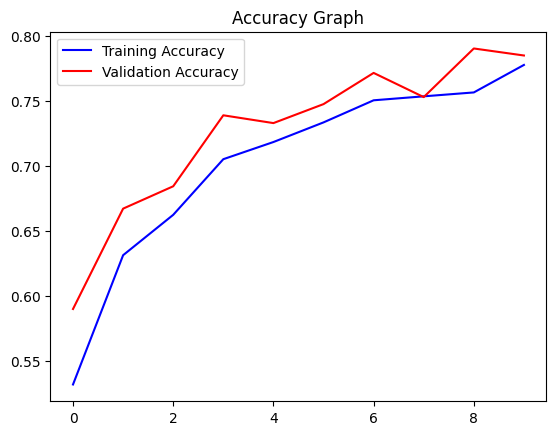

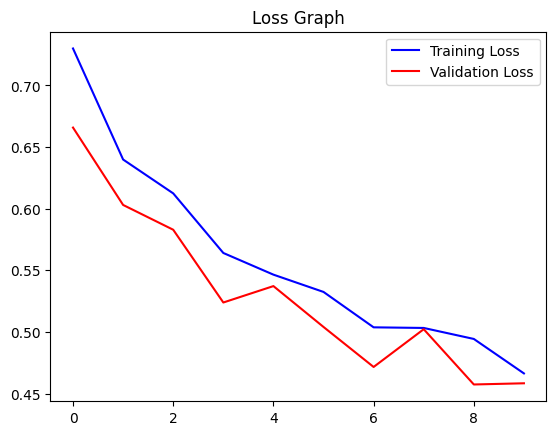

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))

plt.plot(epochs, acc, 'b', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r', label='Validation Accuracy')
plt.title('Accuracy Graph')
plt.legend()
plt.figure()

loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(epochs, loss, 'b', label='Training Loss')
plt.plot(epochs, val_loss, 'r', label='Validation Loss')
plt.title('Loss Graph')
plt.legend()
plt.show()

## Test with Real Image

In [22]:
image_path = "PetImages/test/test.jpg" # path of the image
img = load_img(image_path, target_size=(128, 128))
img = np.array(img)
img = img / 255.0 # normalize the image
img = img.reshape(1, 128, 128, 3) # reshape for prediction
pred = model.predict(img)
if pred[0] > 0.5:
    label = 'Dog'
else:
    label = 'Cat'
print(label)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step
Cat
